In [1]:
# Author: Till Zemann
# License: MIT License
import sys
sys.path.append("..")
from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C
from net.dale_util import RL_Hidden_Buffer

1.12.0


In [5]:
buffer = RL_Hidden_Buffer(10000)
simple_type = 'rnn'
ei_type = 'eisep'
configuration = 'simple'
actor_lr = 0.001
critic_lr = 0.005

info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'

buffer_path = info_path.replace('.pkl', '_buffer1.pkl')
buffer.load(buffer_path)
print(buffer.state.shape)
print(buffer.ptr, buffer.n_h)
# print(buffer.episode_rewards)
print(buffer.reward[:buffer.ptr].mean())

./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/simple_buffer1.pkl size: 10000
(100000, 8)
10000 2
0.0707831908956525


In [6]:
print(buffer.state[200])
### Meaning:
# lander x coordinate
# lander y coordinate
# lander x velocity
# lander y velocity
# lander angle
# lander angular velocity
# left leg contact
# right leg contact
print(buffer.action[0], buffer.action.max())
### Meaning:
# do nothing
# fire left engine
# fire main engine
# fire right engine
print(buffer.hidden_state[0].shape)
print(buffer.reward[0], buffer.done[0])
network_name = 'critic'


[-0.19841823  1.07110453 -0.10161448  0.04452175 -0.03770846 -0.02802375
  0.          0.        ]
[2.] 3.0
(2, 64)
[-5.21622023] [0.]


(10000, 4)
(10000, 12) (100000, 2, 64)
(10000, 64)
x: min -0.65, max 0.55,           mean -0.07, std 0.29
y: min 0.21, max 1.49,           mean 0.87, std 0.28
vx: min -0.83, max 0.81,           mean -0.02, std 0.16
vy: min -0.61, max 0.42,           mean -0.08, std 0.08
a: min -0.28, max 0.31,           mean 0.00, std 0.07
va: min -0.28, max 0.31,           mean 0.00, std 0.08


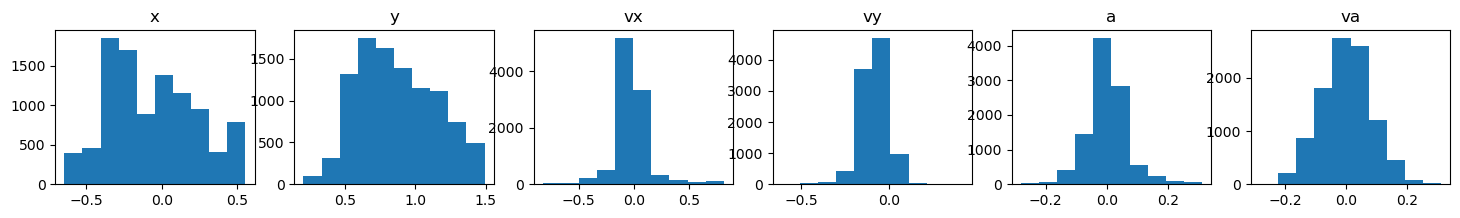

In [7]:
n_action = int(buffer.action.max()+1)
feature_dim = buffer.state.shape[-1] + n_action
buffer_state = buffer.state[:buffer.ptr]
buffer_action = buffer.action[:buffer.ptr]
buffer_done = buffer.done[:buffer.ptr]
buffer_action_onehot = np.eye(n_action)[buffer_action.astype(np.int64).squeeze(-1)]
print(buffer_action_onehot.shape)
features = np.concatenate([buffer_state, buffer_action_onehot], axis=-1)
print(features.shape, buffer.hidden_state.shape)
if network_name == 'critic':
    buffer_hidden = buffer.hidden_state[:buffer.ptr, 0]
elif network_name == 'actor':
    buffer_hidden = buffer.hidden_state[:buffer.ptr, 1]
print(buffer_hidden.shape)
### up is positive y velocity
fig, ax = plt.subplots(1,6, figsize=(18,2))
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
for i in range(6):
    ax[i].hist(buffer_state[:,i])
    print(f'{tick_names[i]}: min {buffer_state[:,i].min():.2f}, max {buffer_state[:,i].max():.2f}, \
          mean {buffer_state[:,i].mean():.2f}, std {buffer_state[:,i].std():.2f}')
    ax[i].set_title(tick_names[i])
plt.show()

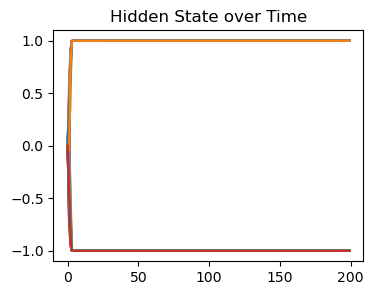

In [8]:
fig, ax = plt.subplots(1,1, figsize=(4,3))
for i in range(buffer_hidden.shape[-1]):
    ax.plot(buffer_hidden[:200,i], label=f'h{i}')
ax.set_title('Hidden State over Time')
# ax.legend()
plt.show()

R^2: 0.17604969468204243
Coefficients: [[-1.11982587e-01  1.30019400e-01 -1.32826408e-01 -4.24701027e-01
   2.55207356e-02 -1.65639782e-02  0.00000000e+00  0.00000000e+00]
 [ 3.54912635e-03  8.24378888e-03  2.00658284e-02  2.58561951e-04
  -2.07387678e-02 -6.70356966e-03  0.00000000e+00  0.00000000e+00]
 [ 3.35441471e-03  8.67743402e-03  2.03054708e-02  4.08826726e-04
  -2.12751759e-02 -6.86094124e-03  0.00000000e+00  0.00000000e+00]
 [-3.73477480e-03 -9.04820087e-03 -2.01002236e-02  8.01558444e-06
   2.06074851e-02  6.73569903e-03  0.00000000e+00  0.00000000e+00]
 [ 1.62210798e-03 -4.60538473e-02  1.18940244e-03  2.12691697e-02
  -2.45940630e-02 -1.29389754e-03  0.00000000e+00  0.00000000e+00]
 [-3.70380520e-03 -9.10887599e-03 -2.02919656e-02 -2.22703034e-04
   2.06714847e-02  6.86764654e-03  0.00000000e+00  0.00000000e+00]
 [ 5.18851307e-02  1.05401625e-01 -2.06240601e-03 -3.48582802e-02
   9.94106182e-02  2.95685263e-03  0.00000000e+00  0.00000000e+00]
 [-3.72289781e-03 -9.20961752e

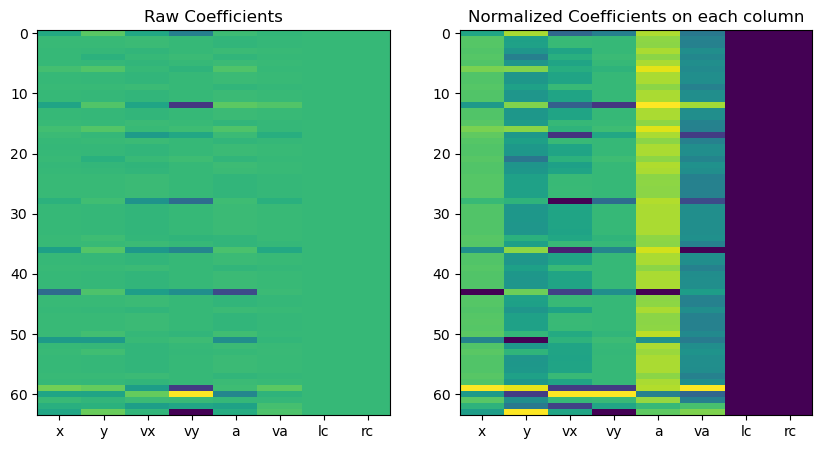

In [10]:
from sklearn.linear_model import LinearRegression
from matplotlib import pyplot as plt
reg = LinearRegression().fit(buffer_state, buffer_hidden)
print('R^2:', reg.score(buffer_state, buffer_hidden))
print('Coefficients:', reg.coef_)
normalized_coefficients = (reg.coef_ - np.min(reg.coef_, axis=0))/(np.max(reg.coef_, axis=0) - np.min(reg.coef_, axis=0)+1e-10)
print('Intercept:', reg.intercept_)
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
fig, ax = plt.subplots(1,2,figsize=(10,5))
ax[0].imshow(reg.coef_, aspect='auto')
ax[0].set_title('Raw Coefficients')
ax[0].set_xticks(np.arange(len(tick_names)))
ax[0].set_xticklabels(tick_names)
ax[1].imshow(normalized_coefficients, aspect='auto')
ax[1].set_title('Normalized Coefficients on each column')
ax[1].set_xticks(np.arange(len(tick_names)))

ax[1].set_xticklabels(tick_names)
plt.show()


[0 0 0 ... 0 0 0]
(4, 64)


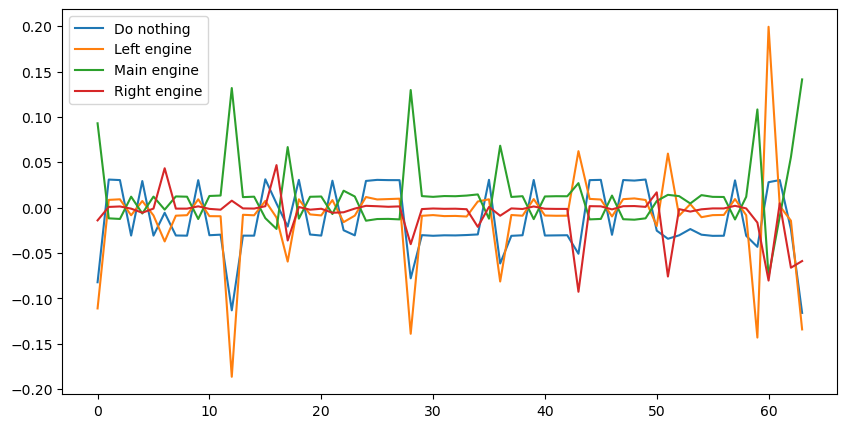

Alignment between action 0 and action 0: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Alignment between action 0 and action 1: [1.         0.99999988 0.9999996  0.99999804 0.99998845 0.99991518
 0.9996714  0.99834742 0.99199823 0.27191694]
Alignment between action 0 and action 2: [1.         0.99999991 0.99999943 0.99999725 0.99999445 0.99998614
 0.99994561 0.99940378 0.99664578 0.34723154]
Alignment between action 0 and action 3: [1.         0.99999987 0.99999958 0.99999714 0.99998758 0.99998409
 0.99959218 0.99947203 0.99590601 0.30115255]
Alignment between action 1 and action 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Alignment between action 1 and action 2: [1.         0.99999987 0.99999938 0.99998984 0.99997885 0.99991393
 0.99966563 0.9981638  0.99479074 0.97003766]
Alignment between action 1 and action 3: [1.         0.99999913 0.99999891 0.99999836 0.99999084 0.9998936
 0.9994423  0.99394707 0.99187359 0.98962429]
Alignment between action 2 and action 2: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Alignment be

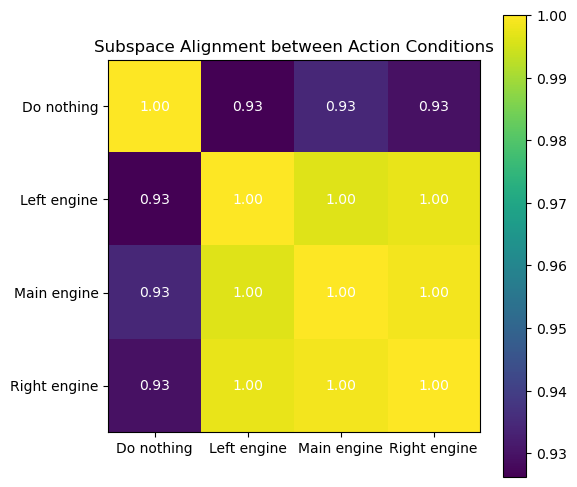

In [11]:
action_specific_idxs = [np.where(buffer_action.squeeze(-1)==i,1,0) for i in range(n_action)]
print(action_specific_idxs[0])
def action_specific_selectivity(i):
    idxs = action_specific_idxs[i]
    positive_hidden = buffer_hidden[idxs==1]
    negative_hidden = buffer_hidden[idxs==0]
    selectivity = (positive_hidden.mean(axis=0) - negative_hidden.mean(axis=0)) / (positive_hidden.std(axis=0) + negative_hidden.std(axis=0) + 1e-6)
    return selectivity
action_selectivities = [action_specific_selectivity(i) for i in range(n_action)]
action_selectivity_matrix = np.stack(action_selectivities, axis=0)
print(action_selectivity_matrix.shape)
fig, ax = plt.subplots(1,1,figsize=(10,5))
action_names = ['Do nothing', 'Left engine', 'Main engine', 'Right engine']
for i in range(n_action):
    
    ax.plot(action_selectivities[i], label=action_names[i])
ax.legend()
plt.show()
from sklearn.decomposition import PCA
from rl.rl_util import subspace_alignments_across_index
alignments = subspace_alignments_across_index(buffer_hidden, action_specific_idxs)
fig, ax = plt.subplots(1,1,figsize=(6,6))
im = ax.imshow(alignments, cmap='viridis')
ax.set_xticks(np.arange(n_action))
ax.set_yticks(np.arange(n_action))
ax.set_xticklabels(action_names)
ax.set_yticklabels(action_names)
for i in range(n_action):
    for j in range(n_action):
        text = ax.text(j, i, f'{alignments[i, j]:.2f}',
                       ha="center", va="center", color="w")
fig.colorbar(im)
ax.set_title('Subspace Alignment between Action Conditions')
plt.show()

In [13]:
from net.a2c import A2C_singleRNN


info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
with open(info_path, 'rb') as f:
    info = pkl.load(f)
net_state_dicts = info['net_state_dict']
obs_dim = buffer_state.shape[-1]
action_dim = n_action
device = 'cpu'
n_envs = 1
hidden_size = buffer_hidden.shape[-1]
seed = 1
agent = A2C(obs_dim, action_dim, device, critic_lr, actor_lr, n_envs, hidden_size,
            configuration, simple_type, ei_type)
agent.load_state_dict(net_state_dicts[seed])
agent.eval()

Using <class 'net.rnncell_variant.EIRNNCell'> for actor and critic


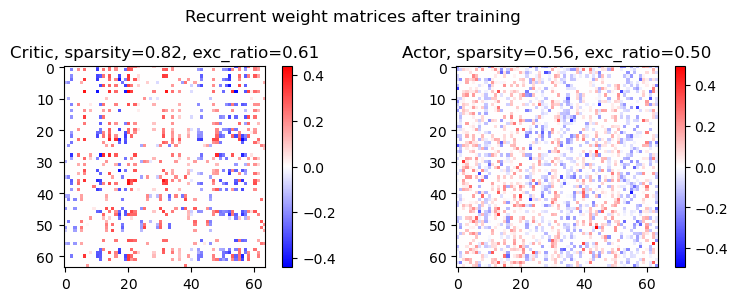

In [14]:
def score(weight, module):
    sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
    exc_ratio = -1
    if hasattr(module, 'get_ei_entropy_loss'):
        eimask_logit = module.eimask_logit.detach().cpu().numpy()
        exc_ratio = np.mean(eimask_logit[:,0]>eimask_logit[:,1])
    return sparsity, exc_ratio

W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()
# W_critic = agent.critic_actor.get_actual_weight().detach().cpu().numpy()
sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic)
sparsity_actor, exc_ratio_actor = score(W_actor, agent.actor)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8, 3))
axs[0].set_title(f"Critic, sparsity={sparsity_critic:.2f}, exc_ratio={exc_ratio_critic:.2f}")
limit = np.max(np.abs(W_critic))
im0 = axs[0].imshow(W_critic, vmin=-limit, vmax=limit, cmap='bwr')
plt.colorbar(im0, ax=axs[0])
axs[1].set_title(f"Actor, sparsity={sparsity_actor:.2f}, exc_ratio={exc_ratio_actor:.2f}")
limit = np.max(np.abs(W_actor))
im1 = axs[1].imshow(W_actor, vmin=-limit, vmax=limit, cmap='bwr')
plt.colorbar(im1, ax=axs[1])
plt.suptitle("Recurrent weight matrices after training")
plt.tight_layout()
plt.show()

In [16]:
if network_name == 'actor':
    W = W_actor
elif network_name == 'critic':
    W = W_critic


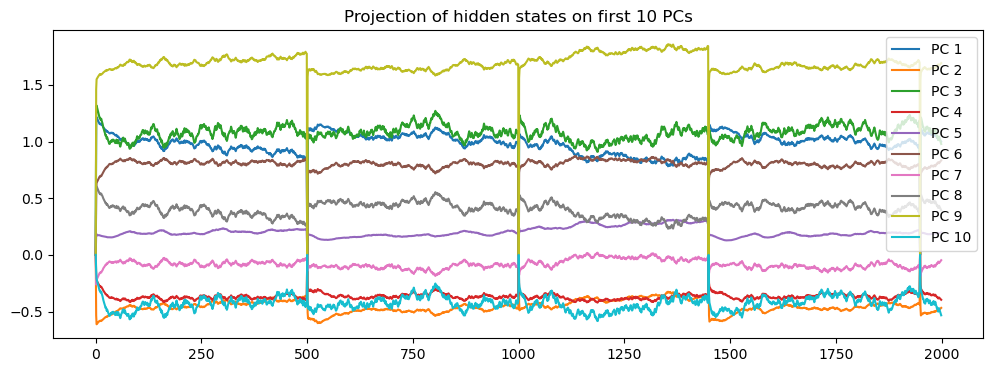

Separation decorrelation of all PCs: 0.50533404259881


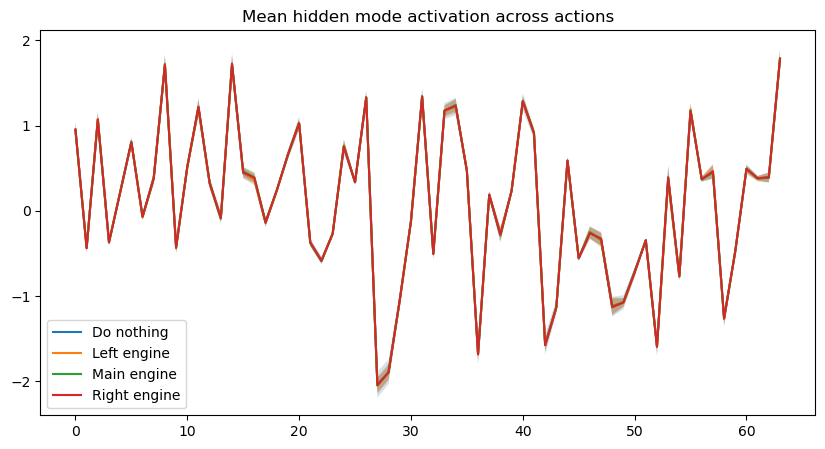

In [17]:
u, s, vh = np.linalg.svd(W)
hidden_projection_on_pc = buffer_hidden @ u.T

from rl.rl_util import sep_corr
fig, ax = plt.subplots(1,1, figsize=(12,4))
for i in range(10):
    ax.plot(hidden_projection_on_pc[:2000, i], label=f'PC {i+1}')
ax.set_title('Projection of hidden states on first 10 PCs')
ax.legend()
plt.show()
print('Separation decorrelation of all PCs:', sep_corr(hidden_projection_on_pc))
action_specific_hidden_mode_activation = [hidden_projection_on_pc[action_specific_idxs[i]==1] for i in range(n_action)]
mean_hidden_mode_activation = [action_specific_hidden_mode_activation[i].mean(axis=0) for i in range(n_action)]
std_hidden_mode_activation = [action_specific_hidden_mode_activation[i].std(axis=0) for i in range(n_action)]
fig, ax = plt.subplots(1,1, figsize=(10,5))
for i in range(n_action):
    ax.plot(mean_hidden_mode_activation[i], label=action_names[i])
    ax.fill_between(np.arange(len(mean_hidden_mode_activation[i])), mean_hidden_mode_activation[i]-std_hidden_mode_activation[i],
                    mean_hidden_mode_activation[i]+std_hidden_mode_activation[i], alpha=0.2)
ax.set_title('Mean hidden mode activation across actions')
ax.legend()
plt.show()


0.03158776443979147
(64,)
[ 0  3  8  2  0 51]


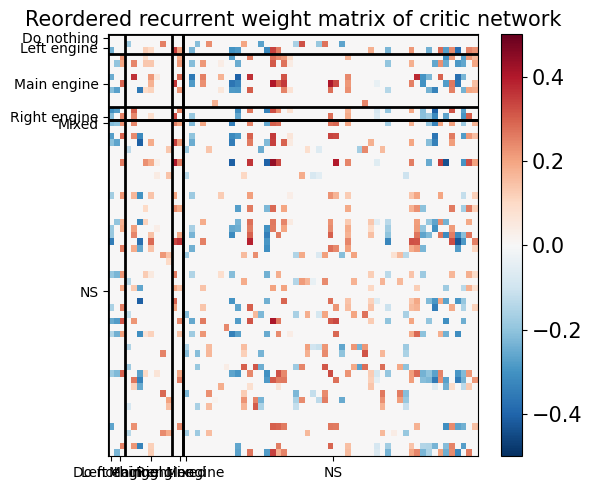

In [18]:
threshold = np.std(action_selectivity_matrix)*0.8
print(threshold)
past_threshold = np.where(action_selectivity_matrix>threshold, 1, 0).sum(0)
max_action = np.argmax(action_selectivity_matrix, 0)
print(max_action.shape)
non_selective_mask = (past_threshold==0)
mixed_selective_mask = (past_threshold>1)
non_selective_neurons = np.where(non_selective_mask)[0]

# other_choice_neurons = np.unique(np.concatenate([action_selective_neurons[i] for i in range(n_action) if i != 2]))
mixed_selective_neurons = np.where(mixed_selective_mask)[0]
action_selective_neurons = [np.where((max_action==i)&(~non_selective_mask)&(~mixed_selective_mask))[0] for i in range(n_action)]
action_neurons = action_selective_neurons + [mixed_selective_neurons, non_selective_neurons]
action_perm = np.concatenate(action_neurons)
n_neurons = np.array([len(x) for x in action_neurons])
# action_selective_neurons = [np.where((action_selectivities[i])>threshold)[0] for i in range(n_action)]
# main_engine_neurons = action_selective_neurons[2]

# main_engine_neurons = np.setdiff1d(main_engine_neurons, np.concatenate([mixed_selective_neurons, non_selective_neurons]))
# other_choice_neurons = np.setdiff1d(other_choice_neurons, np.concatenate([mixed_selective_neurons, non_selective_neurons]))


N = W.shape[0]
all_neurons = np.arange(N)
# action_neurons = [main_engine_neurons, other_choice_neurons, mixed_selective_neurons, non_selective_neurons]
# action_perm = np.concatenate([main_engine_neurons, other_choice_neurons, mixed_selective_neurons, non_selective_neurons])
reordered_weight = W[np.ix_(action_perm, action_perm)]
fig, ax = plt.subplots(1,1,figsize=(6,5))
limit = np.max(np.abs(reordered_weight))
plt.imshow(reordered_weight, cmap='RdBu_r', aspect='auto', vmin=-0.5, vmax=0.5)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=15)
# n_neurons = np.array([len(main_engine_neurons), len(other_choice_neurons), len(mixed_selective_neurons), len(non_selective_neurons)])
phase_boundaries = np.cumsum(n_neurons)
for boundary in phase_boundaries[:-1]:
    plt.axhline(boundary-0.5, color='k', linewidth=2)
    plt.axvline(boundary-0.5, color='k', linewidth=2)
print(n_neurons)
action_related_names = action_names+['Mixed', 'NS']
plt.xticks(phase_boundaries-n_neurons/2, action_related_names)
plt.yticks(phase_boundaries-n_neurons/2, action_related_names)
plt.title(f'Reordered recurrent weight matrix of {network_name} network', fontsize=15)
plt.tight_layout()
plt.show()

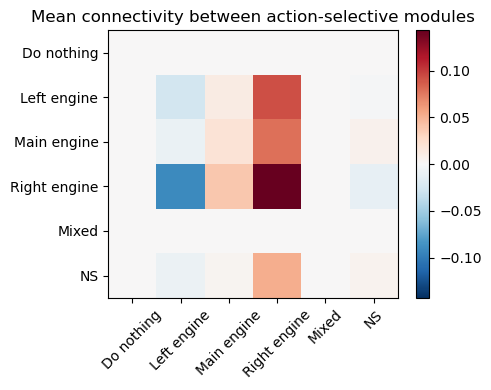

In [19]:
# Build group list: 0..n_phase-1, 'mixed', 'non-selective'
groups = action_neurons
n_groups = len(groups)

W_group = np.zeros((n_groups, n_groups))

for p in range(n_groups):        # postsynaptic
    for q in range(n_groups):    # presynaptic
        rows = groups[p]
        cols = groups[q]
        if len(rows) == 0 or len(cols) == 0:
            W_group[p, q] = 0.0
        else:
            sub = W[np.ix_(rows, cols)]
            W_group[p, q] = sub.mean()

fig, ax = plt.subplots(1,1,figsize=(5,4))
limit = np.max(np.abs(W_group))
im = ax.imshow(W_group, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
cbar = plt.colorbar(im)
ax.set_xticks(np.arange(n_groups))
ax.set_yticks(np.arange(n_groups))
ax.set_xticklabels(action_related_names, rotation=45)
ax.set_yticklabels(action_related_names)
ax.set_title('Mean connectivity between action-selective modules')
plt.tight_layout()
plt.show()


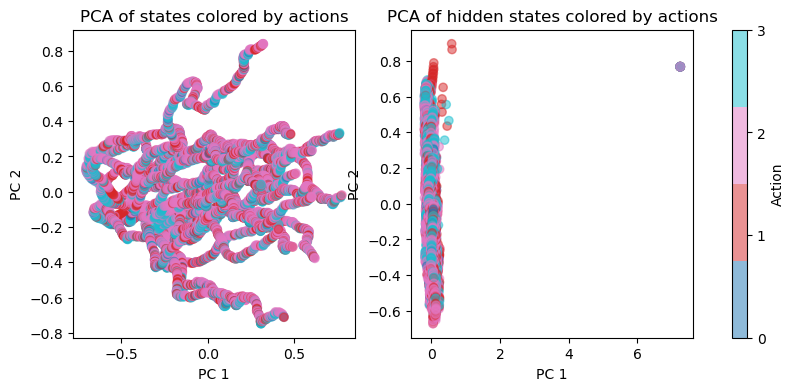

/tmp/ipykernel_22171/3966338742.py:26: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[action].scatter(state_pca[action_idx,0], state_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))


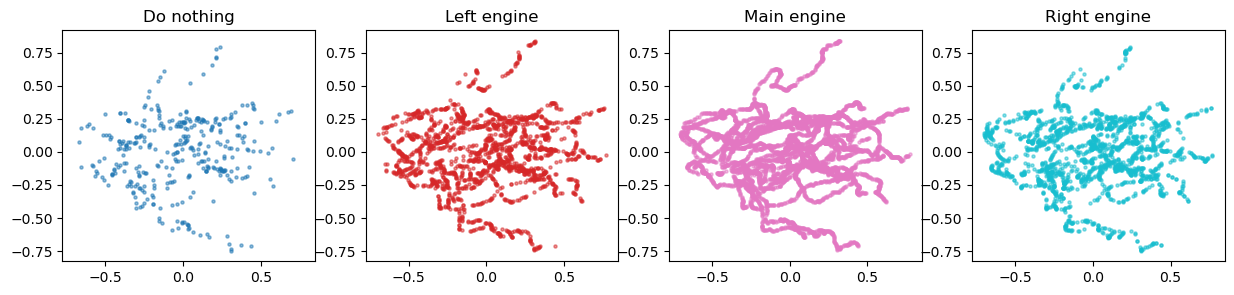

/tmp/ipykernel_22171/3966338742.py:34: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[action].scatter(hidden_pca[action_idx,0], hidden_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))


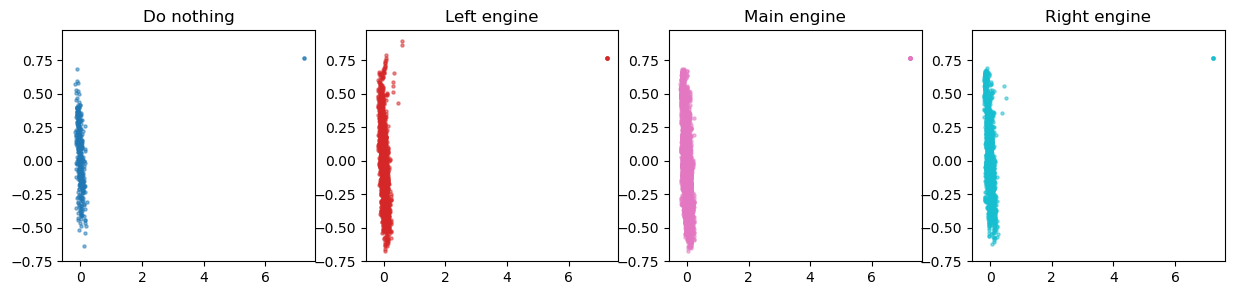

In [20]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
state_pca = pca.fit_transform(buffer_state)
fig, ax = plt.subplots(1,2,figsize=(10,4))
colormap = plt.get_cmap('tab10', n_action)
ax[0].scatter(state_pca[:,0], state_pca[:,1], c=buffer_action.squeeze(-1).astype(np.int64), cmap=colormap, alpha=0.5)
ax[0].set_xlabel('PC 1')
ax[0].set_ylabel('PC 2')
ax[0].set_title('PCA of states colored by actions')
ax0_lim = (ax[0].get_xlim(), ax[0].get_ylim())
pca = PCA(n_components=2)
hidden_pca = pca.fit_transform(buffer_hidden)
s = ax[1].scatter(hidden_pca[:,0], hidden_pca[:,1], c=buffer_action.squeeze(-1).astype(np.int64), cmap=colormap, alpha=0.5)
ax[1].set_xlabel('PC 1')
ax[1].set_ylabel('PC 2')
ax[1].set_title('PCA of hidden states colored by actions')
ax1_lim = (ax[1].get_xlim(), ax[1].get_ylim())
# fig.colorbar(label='Action', ticks=np.arange(n_action), ax=ax[1], cax=ax[1], mappable=s)
plt.colorbar(s, ax=ax, label='Action', ticks=np.arange(n_action))
# plt.tight_layout()
plt.show()
action_names = ['Do nothing', 'Left engine', 'Main engine', 'Right engine']
fig, ax = plt.subplots(1,4, figsize=(15,3))
for action in range(n_action):
    action_idx = np.where(buffer_action.squeeze(-1).astype(np.int64)==action)[0]
    ax[action].scatter(state_pca[action_idx,0], state_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))
    ax[action].set_title(action_names[action])
    ax[action].set_xlim(ax0_lim[0])
    ax[action].set_ylim(ax0_lim[1])
plt.show()
fig, ax = plt.subplots(1,4, figsize=(15,3))
for action in range(n_action):
    action_idx = np.where(buffer_action.squeeze(-1).astype(np.int64)==action)[0]
    ax[action].scatter(hidden_pca[action_idx,0], hidden_pca[action_idx,1], alpha=0.5, s=5, c=colormap(action))
    ax[action].set_title(action_names[action])
    ax[action].set_xlim(ax1_lim[0])
    ax[action].set_ylim(ax1_lim[1])
plt.show()

In [21]:
from rl.rl_util import tag_lunar_lander_phases_batch_2

In [22]:
buffer_phase = tag_lunar_lander_phases_batch_2(
    buffer_state,
    buffer_action,
    buffer_done
)

print(buffer_phase.shape)  # (L,)
print(buffer_phase[:500])
print(np.bincount(buffer_phase))  # count each phase
np.save('buffer_phase.npy', buffer_phase)

(9831,)
[0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1
 1 2 0 0 0 1 1 0 1 1 0 1 0 1 0 1 1 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1
 0 1 0 1 1 0 1 1 0 1 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1 0 0 2 2 2 2 2 2 2 2 2 2
 2 0 0 1 0 0 1 0 0 0 0 1 0 2 2 2 2 1 1 0 2 2 2 2 2 2 2 2 2 1 2 1 1 0 0 0 1
 1 0 1 1 1 0 0 0 1 0 0 0 1 1 1 1 0 0 1 1 1 0 1 1 0 0 1 1 0 0 1 0 1 0 1 0 0
 1 0 1 1 0 1 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 0 0 1 1
 0 0 1 1 0 1 1 0 2 2 0 0 1 0 2 0 2 2 2 2 2 2 2 2 2 1 1 1 1 0 2 2 0 1 1 0 0
 0 0 0 1 0 0 1 1 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 1 0 1 0 0 0 0 1 1 1
 1 1 0 1 1 0 1 1 1 0 1 0 0 0 1 1 1 0 0 1 1 1 0 0 0 1 1 0 0 1 0 2 2 2 0 2 2
 2 2 2 1 1 0 0 1 1 0 1 1 0 0 0 1 1 1 1 0 1 0 0 1 1 0 1 1 0 2 2 2 2 2 2 2 2
 2 2 1 1 0 1 0 0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 0 0 0 1 1 0 1 1 0 0 1
 1 0 1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 1 1 0 1 1
 1 0 0 1 1 0 0 0 

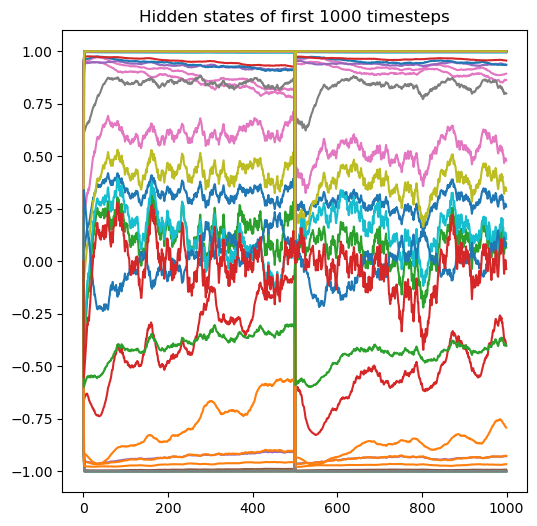

In [23]:
fig, ax = plt.subplots(1,1, figsize=(6,6))
for i in range(buffer_hidden.shape[1]):
    ax.plot(buffer_hidden[:1000, i], label=f'Neuron {i+1}')
ax.set_title('Hidden states of first 1000 timesteps')
# ax.legend()
plt.show()

count: 9831


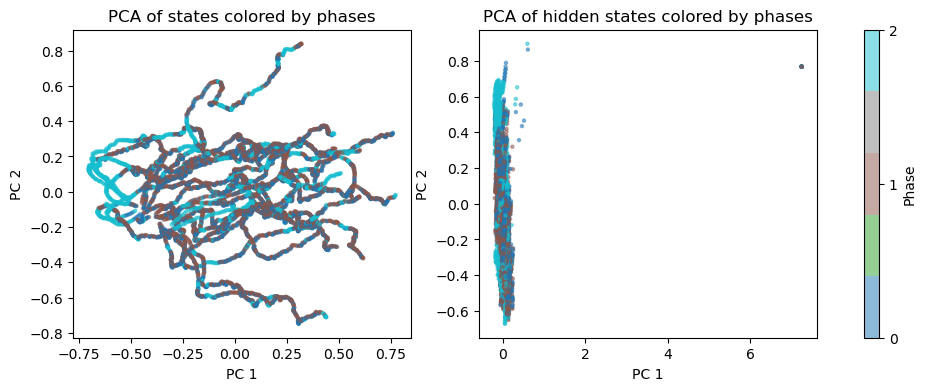

/tmp/ipykernel_22171/1320678949.py:28: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[phase].scatter(state_pca[phase_idx,0], state_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))


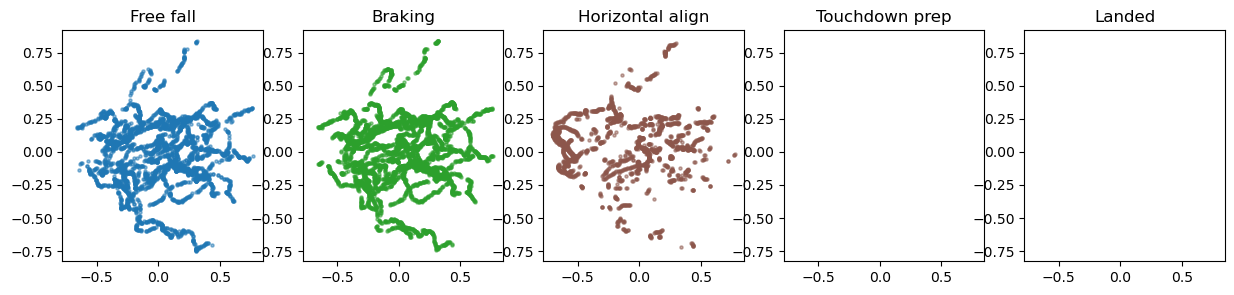

/tmp/ipykernel_22171/1320678949.py:36: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[phase].scatter(hidden_pca[phase_idx,0], hidden_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))


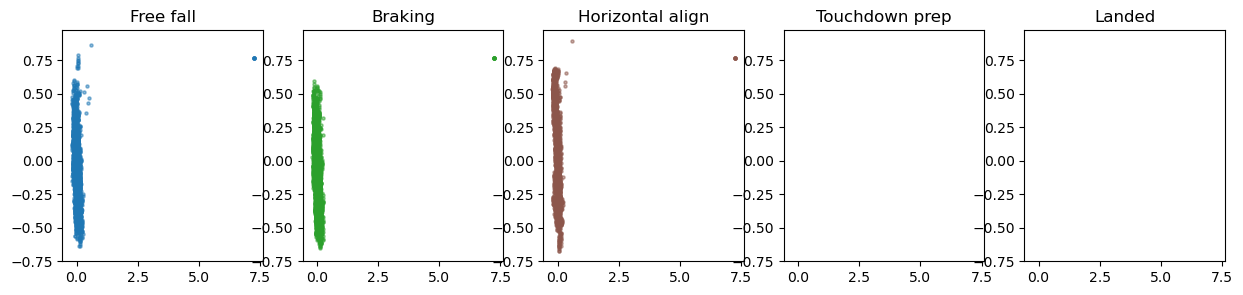

In [24]:
from sklearn.decomposition import PCA
n_phase = 5
pca = PCA(n_components=2)
state_pca = pca.fit_transform(buffer_state)
fig, ax = plt.subplots(1,2,figsize=(12,4))
colormap = plt.get_cmap('tab10', n_phase)
ax[0].scatter(state_pca[:,0], state_pca[:,1], c=buffer_phase, cmap=colormap, alpha=0.5, s=5)
ax[0].set_xlabel('PC 1')
ax[0].set_ylabel('PC 2')
ax[0].set_title('PCA of states colored by phases')
ax0_lim = (ax[0].get_xlim(), ax[0].get_ylim())
pca = PCA(n_components=2)
hidden_pca = pca.fit_transform(buffer_hidden)
print('count:', buffer_hidden.shape[0])
s = ax[1].scatter(hidden_pca[:,0], hidden_pca[:,1], c=buffer_phase, cmap=colormap, alpha=0.5, s=5)
ax[1].set_xlabel('PC 1')
ax[1].set_ylabel('PC 2')
ax[1].set_title('PCA of hidden states colored by phases')
ax1_lim = (ax[1].get_xlim(), ax[1].get_ylim())
# fig.colorbar(label='Action', ticks=np.arange(n_action), ax=ax[1], cax=ax[1], mappable=s)
plt.colorbar(s, ax=ax, label='Phase', ticks=np.arange(n_phase))
# plt.tight_layout()
plt.show()
phase_names = ['Free fall', 'Braking', 'Horizontal align', 'Touchdown prep', 'Landed', 'Crash']
fig, ax = plt.subplots(1,5, figsize=(15,3))
for phase in range(n_phase):
    phase_idx = np.where(buffer_phase==phase)[0]
    ax[phase].scatter(state_pca[phase_idx,0], state_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))
    ax[phase].set_title(phase_names[phase])
    ax[phase].set_xlim(ax0_lim[0])
    ax[phase].set_ylim(ax0_lim[1])
plt.show()
fig, ax = plt.subplots(1,5, figsize=(15,3))
for phase in range(n_phase):
    phase_idx = np.where(buffer_phase==phase)[0]
    ax[phase].scatter(hidden_pca[phase_idx,0], hidden_pca[phase_idx,1], alpha=0.5, s=5, c=colormap(phase))
    ax[phase].set_title(phase_names[phase])
    ax[phase].set_xlim(ax1_lim[0])
    ax[phase].set_ylim(ax1_lim[1])
plt.show()

In [25]:
from rl.rl_util import sep_phase_fisher
sep_fr, idx_count = sep_phase_fisher(buffer_hidden, buffer_phase)
print('Phase counts:', idx_count)
print('Phase separation Fisher ratio in hidden space:', sep_fr)
print('Shuffled control:', sep_phase_fisher(buffer_hidden, buffer_phase[np.random.permutation(len(buffer_phase))])[0])

Phase counts: [3358 4526 1947]
Phase separation Fisher ratio in hidden space: 0.013342396301538304
Shuffled control: 0.0003309278997995436


[1 1 1 ... 0 0 0]


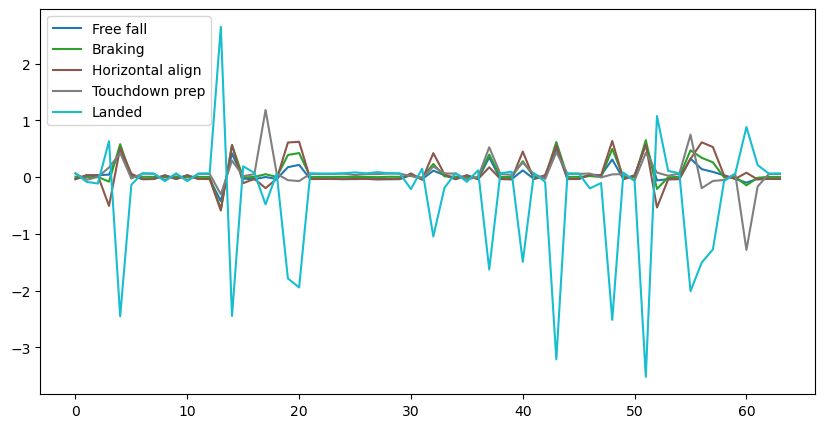

Alignment between action 0 and action 0: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Alignment between action 0 and action 1: [1.         0.99999986 0.99999597 0.99995899 0.99992384 0.99957342
 0.99888444 0.99797576 0.99006513 0.43019404]
Alignment between action 0 and action 2: [0.99999999 0.9999974  0.99996927 0.99992312 0.99981979 0.99863967
 0.9980236  0.93570323 0.44671366 0.36791992]
Alignment between action 0 and action 3: [0.99999949 0.99988715 0.99974541 0.99860139 0.99757978 0.99603995
 0.96736738 0.94524812 0.66854677 0.25529983]
Alignment between action 0 and action 4: [0.99999768 0.99978983 0.99793091 0.99143301 0.97348751 0.93134582
 0.6550473  0.52734083 0.20590934 0.05217685]
Alignment between action 1 and action 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Alignment between action 1 and action 2: [0.99999999 0.99999868 0.99997639 0.99988116 0.99968163 0.9991537
 0.99645593 0.93888131 0.89975179 0.40867024]
Alignment between action 1 and action 3: [0.99999981 0.99997661 0.99966686 0.99937563

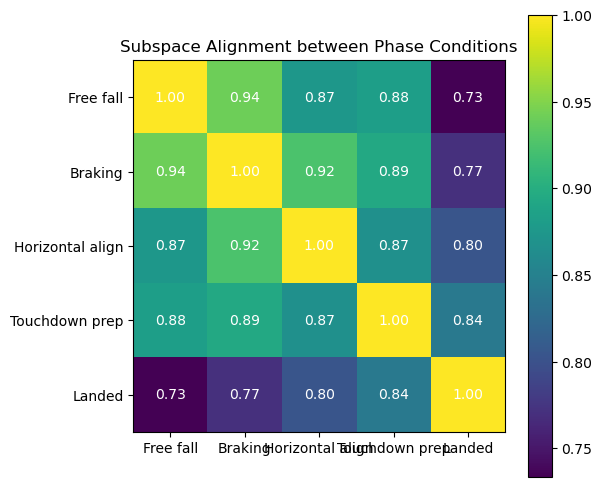

In [19]:
phase_specific_idxs = [np.where(buffer_phase==i,1,0) for i in range(n_phase)]
print(phase_specific_idxs[0])
def specific_selectivity(i):
    idxs = phase_specific_idxs[i]
    positive_hidden = buffer_hidden[idxs==1]
    negative_hidden = buffer_hidden[idxs==0]
    selectivity = (positive_hidden.mean(axis=0) - negative_hidden.mean(axis=0)) / (positive_hidden.std(axis=0) + negative_hidden.std(axis=0) + 1e-6)
    return selectivity
phase_selectivities = [specific_selectivity(i) for i in range(n_phase)]
fig, ax = plt.subplots(1,1,figsize=(10,5))
phase_names = ['Free fall', 'Braking', 'Horizontal align', 'Touchdown prep', 'Landed']
colors = plt.get_cmap('tab10', n_phase)
for i in range(len(phase_names)):
    ax.plot(phase_selectivities[i], label=phase_names[i], color=colors(i))
ax.legend()
plt.show()
alignments = subspace_alignments_across_index(buffer_hidden, phase_specific_idxs)
fig, ax = plt.subplots(1,1,figsize=(6,6))
im = ax.imshow(alignments, cmap='viridis')
ax.set_xticks(np.arange(n_phase))
ax.set_yticks(np.arange(n_phase))
ax.set_xticklabels(phase_names)
ax.set_yticklabels(phase_names)
for i in range(n_phase):
    for j in range(n_phase):
        text = ax.text(j, i, f'{alignments[i, j]:.2f}',
                       ha="center", va="center", color="w")
fig.colorbar(im)
ax.set_title('Subspace Alignment between Phase Conditions')
plt.show()

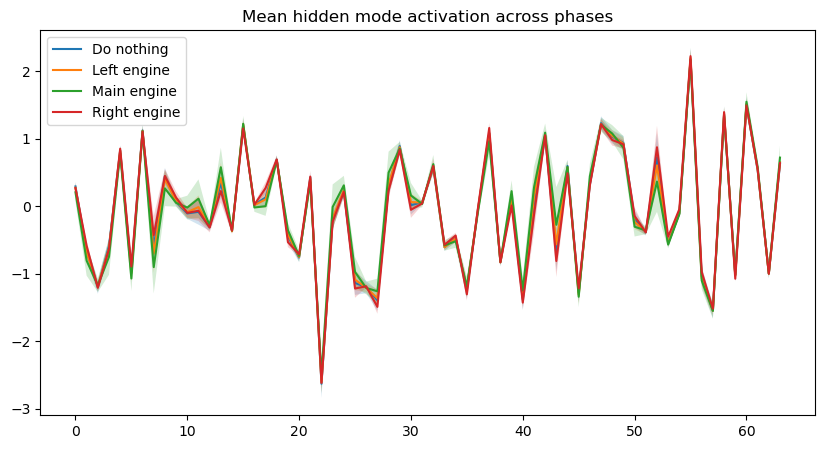

In [20]:
phase_specific_hidden_mode_activation = [hidden_projection_on_pc[phase_specific_idxs[i]==1] for i in range(n_phase)]
mean_hidden_mode_activation = [phase_specific_hidden_mode_activation[i].mean(axis=0) for i in range(n_phase)]
std_hidden_mode_activation = [phase_specific_hidden_mode_activation[i].std(0) for i in range(n_phase)]
fig, ax = plt.subplots(1,1, figsize=(10,5))
for i in range(n_action):
    ax.plot(mean_hidden_mode_activation[i], label=action_names[i])
    ax.fill_between(np.arange(len(mean_hidden_mode_activation[i])), mean_hidden_mode_activation[i]-std_hidden_mode_activation[i],
                    mean_hidden_mode_activation[i]+std_hidden_mode_activation[i], alpha=0.2)
ax.set_title('Mean hidden mode activation across phases')
ax.legend()
plt.show()

In [21]:
# selectivities: list length n_phase, each [hidden_size]
phase_selectivity_matrix = np.stack(phase_selectivities, axis=0)  # shape [n_phase, N]
n_phase, N = phase_selectivity_matrix.shape
print(np.nanstd(phase_selectivity_matrix))
thr = np.nanstd(phase_selectivity_matrix)*0.8 # same as before, or adjust
past_threshold = (phase_selectivity_matrix > thr).sum(0)
mixed_mask = (past_threshold>1)
mixed_neurons = np.where(mixed_mask)[0]
non_selective_mask = (past_threshold==0)
non_selective_neurons = np.where(non_selective_mask)[0]
max_phase = np.argmax(phase_selectivity_matrix, axis=0)


# # Absolute selectivity for grouping
# abs_sel = np.abs(phase_selectivity_matrix)           # [n_phase, N]
# max_phase = np.argmax(abs_sel, axis=0)    # [N], 0..n_phase-1
# max_val   = np.max(abs_sel, axis=0)       # [N]

# # Non-selective: no phase with |sel|>thr
# non_selective_mask = max_val <= thr
# non_selective_neurons = np.where(non_selective_mask)[0]

# Phase-specific neurons: prefer one phase & pass threshold
phase_neurons = [np.where((max_phase==i) & (~mixed_mask) & (~non_selective_mask))[0] for i in range(n_phase)]

# Mixed-selective: strong for >1 phase (optional)
# strong_mask = abs_sel > thr              # [n_phase, N]
# n_strong = strong_mask.sum(axis=0)       # how many phases each neuron is strongly tuned to
# mixed_mask = n_strong > 1
# mixed_selective_neurons = np.where(mixed_mask & (~non_selective_mask))[0]

# Final permutation

phase_perm = np.concatenate(phase_neurons + [mixed_neurons] + [non_selective_neurons])
assert len(phase_perm) == N


0.519260621900175


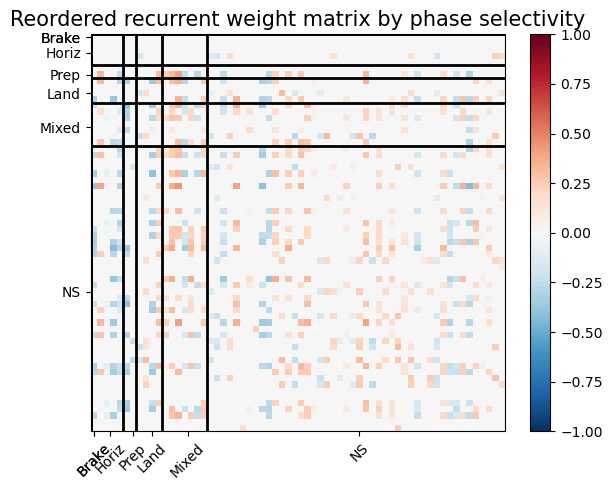

In [22]:
reordered_weight = W[np.ix_(phase_perm, phase_perm)]

fig, ax = plt.subplots(1,1,figsize=(6,5))
limit = np.max(np.abs(reordered_weight))
plt.imshow(reordered_weight, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=10)

# Block boundaries
phase_group_sizes = np.array([len(g) for g in phase_neurons] + [len(mixed_neurons), len(non_selective_neurons)])
phase_boundaries = np.cumsum(phase_group_sizes)

for b in phase_boundaries[:-1]:
    plt.axhline(b - 0.5, color='k', linewidth=2)
    plt.axvline(b - 0.5, color='k', linewidth=2)

centers = phase_boundaries - phase_group_sizes / 2

phase_names = ['Free', 'Brake', 'Horiz', 'Prep', 'Land']
xtick_labels = phase_names + ['Mixed', 'NS']
plt.xticks(centers, xtick_labels, rotation=45)
plt.yticks(centers, xtick_labels)

plt.title('Reordered recurrent weight matrix by phase selectivity', fontsize=15)
plt.tight_layout()
plt.show()


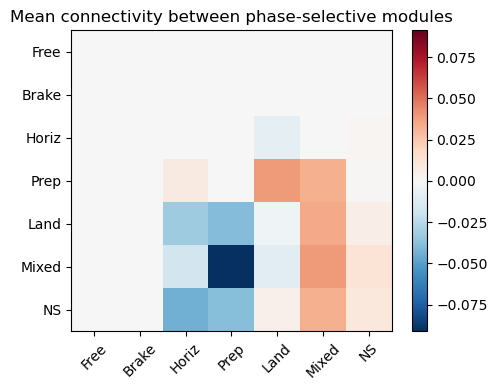

In [23]:
# Build group list: 0..n_phase-1, 'mixed', 'non-selective'
groups = phase_neurons + [mixed_neurons, non_selective_neurons]
n_groups = len(groups)

W_group = np.zeros((n_groups, n_groups))

for p in range(n_groups):        # postsynaptic
    for q in range(n_groups):    # presynaptic
        rows = groups[p]
        cols = groups[q]
        if len(rows) == 0 or len(cols) == 0:
            W_group[p, q] = 0.0
        else:
            sub = W[np.ix_(rows, cols)]
            W_group[p, q] = sub.mean()

fig, ax = plt.subplots(1,1,figsize=(5,4))
limit = np.max(np.abs(W_group))
im = ax.imshow(W_group, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
cbar = plt.colorbar(im)
ax.set_xticks(np.arange(n_groups))
ax.set_yticks(np.arange(n_groups))
ax.set_xticklabels(xtick_labels, rotation=45)
ax.set_yticklabels(xtick_labels)
ax.set_title('Mean connectivity between phase-selective modules')
plt.tight_layout()
plt.show()


[[-3.63476877e-02  3.26038382e-02  3.52768792e-02  4.43247097e-02
   4.60955401e-01  3.14805403e-02 -3.77457598e-02 -3.29815921e-02
   3.28803539e-02 -3.19226591e-02  3.47632808e-02 -3.18053100e-02
  -3.23541036e-02 -4.24035075e-01  4.19621968e-01 -2.66494475e-02
  -3.65391672e-02  2.39185169e-03 -3.24235153e-02  1.75936840e-01
   2.16054163e-01 -3.36670479e-02 -3.18536981e-02 -3.20271320e-02
  -3.70374432e-02 -3.17413500e-02 -3.22582252e-02 -3.27784417e-02
  -3.67177296e-02 -3.56298775e-02  3.92251257e-02 -3.52429057e-02
   1.14461437e-01  3.46444950e-02 -3.76348424e-02  3.45237361e-02
  -3.75287397e-02  3.49226705e-01 -3.33983852e-02 -3.62948727e-02
   1.19588027e-01 -3.23249910e-02  3.16303930e-02  5.05047141e-01
  -3.43531980e-02 -3.29550388e-02  4.46856797e-02  3.43407749e-02
   3.10810633e-01 -3.37319809e-02  3.27041242e-02  5.67507030e-01
  -5.69691054e-02 -3.50203315e-02 -3.52048928e-02  3.27023226e-01
   1.41332356e-01  9.30453971e-02  3.30302080e-02 -3.19748252e-02
  -9.66480

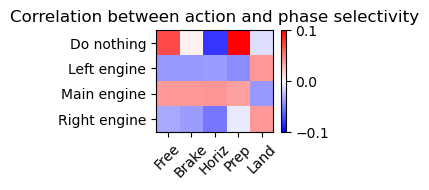

In [24]:
print(phase_selectivity_matrix)
correlation_matrix = action_selectivity_matrix @ phase_selectivity_matrix.T  # [n_action, n_phase]
correlation_matrix = np.where(np.isnan(correlation_matrix), 0, correlation_matrix)
column_norm = np.linalg.norm(correlation_matrix, axis=1, keepdims=True)
row_norm = np.linalg.norm(correlation_matrix, axis=0, keepdims=True)
correlation_matrix_normalized = correlation_matrix/column_norm/row_norm
fig, ax = plt.subplots(1,1,figsize=(3,2))
cbar = ax.imshow(correlation_matrix_normalized, cmap='bwr', aspect='auto', vmin=-0.1, vmax=0.1)
plt.colorbar(cbar, ax=ax)
ax.set_xticks(np.arange(n_phase))
ax.set_yticks(np.arange(n_action))
ax.set_xticklabels(phase_names, rotation=45)
ax.set_yticklabels(action_names)
plt.title('Correlation between action and phase selectivity')
plt.tight_layout()
plt.show()

R^2: 0.26289322986228963
Coefficients: (64, 8)
(64,)


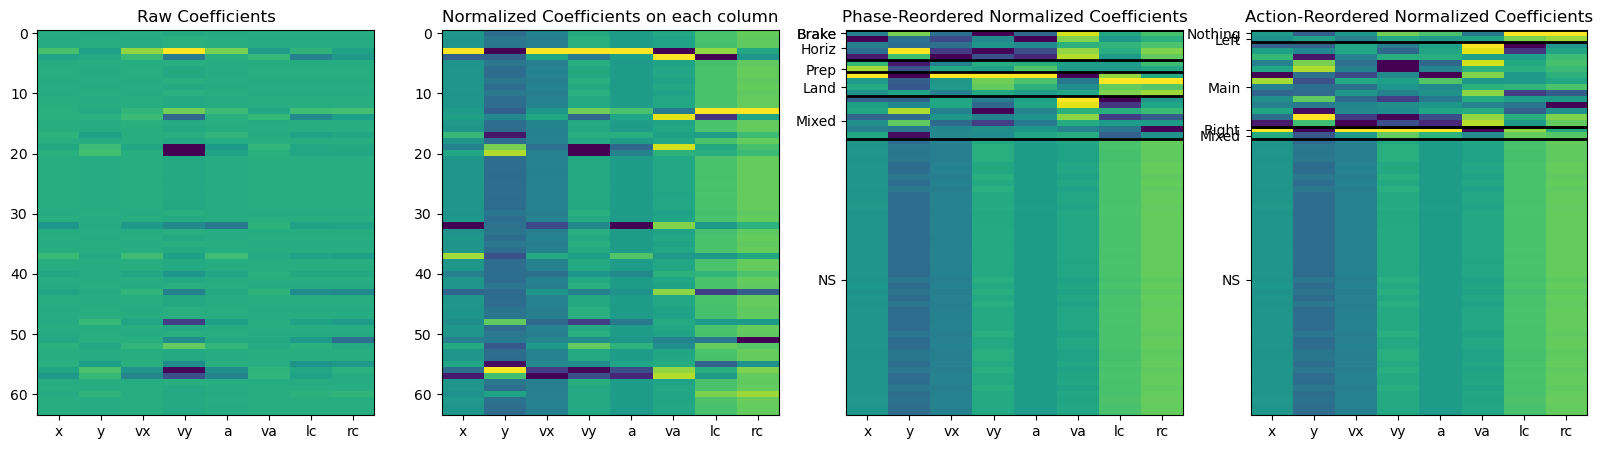

In [25]:
from sklearn.linear_model import LinearRegression
from matplotlib import pyplot as plt
reg = LinearRegression().fit(buffer_state, buffer_hidden)
print('R^2:', reg.score(buffer_state, buffer_hidden))
print('Coefficients:', reg.coef_.shape)
normalized_coefficients = (reg.coef_ - np.min(reg.coef_, axis=0))/(np.max(reg.coef_, axis=0) - np.min(reg.coef_, axis=0)+1e-10)
print(phase_perm.shape)
phase_reorder_coefficients = normalized_coefficients[phase_perm]
# print('Intercept:', reg.intercept_)
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
fig, ax = plt.subplots(1,4,figsize=(20,5))
ax[0].imshow(reg.coef_, aspect='auto')
ax[0].set_title('Raw Coefficients')
ax[0].set_xticks(np.arange(len(tick_names)))
ax[0].set_xticklabels(tick_names)
ax[1].imshow(normalized_coefficients, aspect='auto')
ax[1].set_title('Normalized Coefficients on each column')
ax[1].set_xticks(np.arange(len(tick_names)))
ax[1].set_xticklabels(tick_names)
ax[2].imshow(phase_reorder_coefficients, aspect='auto')
ax[2].set_title('Phase-Reordered Normalized Coefficients')
ax[2].set_xticks(np.arange(len(tick_names)))
ax[2].set_xticklabels(tick_names)
phase_group_sizes = np.array([len(g) for g in phase_neurons] + [len(mixed_neurons), len(non_selective_neurons)])
phase_boundaries = np.cumsum(phase_group_sizes)

for b in phase_boundaries[:-1]:
    ax[2].axhline(b - 0.5, color='k', linewidth=2)

centers = phase_boundaries - phase_group_sizes / 2

phase_names = ['Free', 'Brake', 'Horiz', 'Prep', 'Land']
ytick_labels = phase_names + ['Mixed', 'NS']
ax[2].set_yticks(centers)
ax[2].set_yticklabels(ytick_labels)

action_reorder_coefficients = normalized_coefficients[action_perm]
ax[3].imshow(action_reorder_coefficients, aspect='auto')
ax[3].set_title('Action-Reordered Normalized Coefficients')
ax[3].set_xticks(np.arange(len(tick_names)))
ax[3].set_xticklabels(tick_names)
action_group_sizes = n_neurons
assert sum(action_group_sizes)==N
action_boundaries = np.cumsum(action_group_sizes)
for b in action_boundaries[:-1]:
    ax[3].axhline(b - 0.5, color='k', linewidth=2)
centers = action_boundaries - np.array(action_group_sizes) / 2
action_related_names = ['Nothing', 'Left', 'Main', 'Right', 'Mixed', 'NS']
ax[3].set_yticks(centers)
ax[3].set_yticklabels(action_related_names)
plt.show()

Abnormal Detection


In [26]:
from rl.rl_util import event_selectivity
# Assume:
# buffer_state: [L, state_dim], state[:,4] = angle
# buffer_action: [L, 1] or [L,]
# buffer_hidden: [L, hidden_size]

angle = buffer_state[:, 4]
action = buffer_action.reshape(-1).astype(int)

tilt_thr = 0.2

left_over_tilt = angle > tilt_thr
right_engine = (action == 3)

# (A) Purely state-based "left abnormal" event:
left_abnormal = left_over_tilt

# (B) "left abnormal + corrective action" event:
left_abnormal_corr = left_over_tilt & right_engine

# Use (B) if you want neurons that are specifically active when the network is correcting.
event_mask_left = left_abnormal_corr
print(left_abnormal.sum(), event_mask_left.sum())
if event_mask_left.sum() < 50:  # fallback if too few samples
    print("Too few left_abnormal_corr events, falling back to state-only left_abnormal.")
    event_mask_left = left_abnormal

left_sel = event_selectivity(buffer_hidden, event_mask_left)  # [hidden_size]


358 247


In [27]:
right_over_tilt = angle < -tilt_thr
right_abnormal = right_over_tilt
left_engine = (action == 1)

right_abnormal_corr = right_over_tilt & left_engine
event_mask_right = right_abnormal_corr
print(right_over_tilt.sum(), event_mask_right.sum())
if event_mask_right.sum() < 50:
    print("Too few right_abnormal_corr events, fallback to state-only.")
    event_mask_right = right_abnormal

right_sel = event_selectivity(buffer_hidden, event_mask_right)
tilt_specific_idx = [np.where(left_abnormal_corr,1,0), np.where(right_abnormal_corr,1,0)]  # left, right

331 198


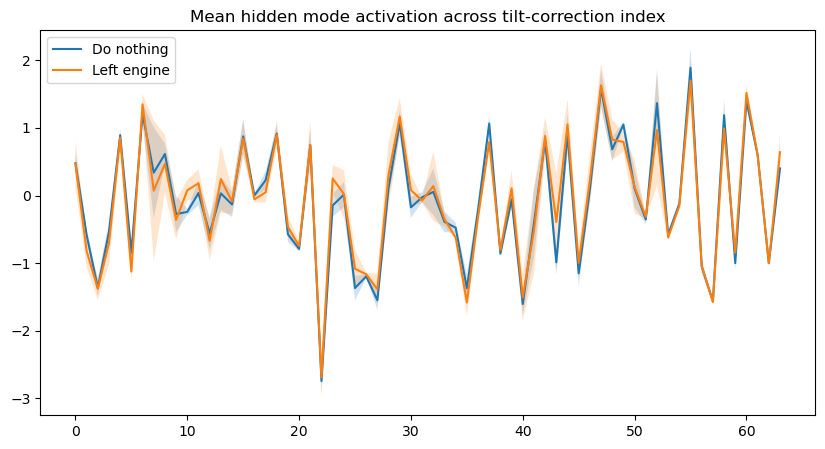

In [28]:
tilt_specific_hidden_mode_activation = [hidden_projection_on_pc[tilt_specific_idx[i]==1] for i in range(2)]
mean_hidden_mode_activation = [tilt_specific_hidden_mode_activation[i].mean(axis=0) for i in range(2)]
std_hidden_mode_activation = [tilt_specific_hidden_mode_activation[i].std(0) for i in range(2)]
fig, ax = plt.subplots(1,1, figsize=(10,5))
for i in range(2):
    ax.plot(mean_hidden_mode_activation[i], label=action_names[i])
    ax.fill_between(np.arange(len(mean_hidden_mode_activation[i])), mean_hidden_mode_activation[i]-std_hidden_mode_activation[i],
                    mean_hidden_mode_activation[i]+std_hidden_mode_activation[i], alpha=0.2)
ax.set_title('Mean hidden mode activation across tilt-correction index')
ax.legend()
plt.show()

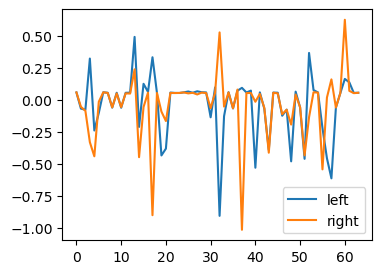

left threshold: 0.1884593761164877
Top left-over-tilt-correction neurons: [ 3 13 17 52] [0.32430247 0.49367633 0.3343771  0.36821426]
right threshold: 0.1973348222906695
Top right-over-tilt-correction neurons: [13 32 60] [0.2401971  0.52874344 0.62740432]
(58,)
Alignment between action 0 and action 0: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Alignment between action 0 and action 1: [0.99999997 0.99996292 0.99933656 0.99867132 0.98490147 0.94286258
 0.83421877 0.69955655 0.50998127 0.23960186]
Alignment between action 1 and action 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


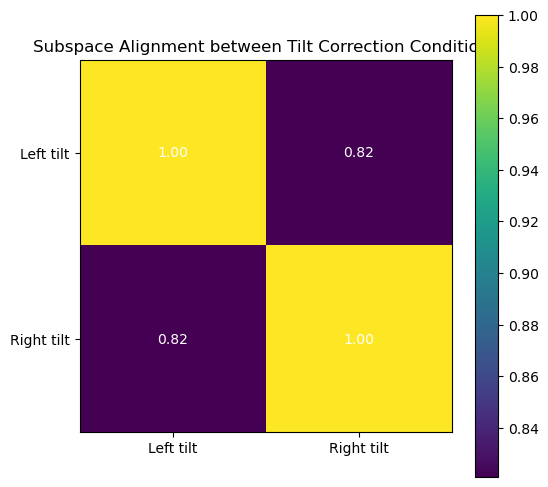

In [29]:
fig, ax = plt.subplots(1,1,figsize=(4,3))
ax.plot(left_sel, label='left')
ax.plot(right_sel, label='right')
plt.legend()
plt.show()

H = buffer_hidden.shape[1]
k = 15

# Sort by absolute selectivity
# idx_sorted = np.argsort(-np.abs(left_sel))
# top_left_neurons = idx_sorted[:k]
tilt_selectivity_matrix = np.zeros((2, H))
left_threshold = np.std(left_sel)*0.8
print('left threshold:', left_threshold)
left_tilt_mask = np.where(left_sel>left_threshold, 1, 0)
tilt_selectivity_matrix[0] = left_tilt_mask
top_left_neurons = np.where(left_sel>left_threshold)[0]
exc_inh_mask_left = np.where(left_sel[top_left_neurons] > 0, 1, 0)


print("Top left-over-tilt-correction neurons:", top_left_neurons, left_sel[top_left_neurons])
# idx_sorted = np.argsort(-np.abs(right_sel))
# top_right_neurons = idx_sorted[:k]
right_threshold = np.std(right_sel)*0.8
print('right threshold:', right_threshold)
right_tilt_mask = np.where(right_sel>right_threshold, 1, 0)
tilt_selectivity_matrix[1] = right_tilt_mask
top_right_neurons = np.where(right_sel>right_threshold)[0]
exc_inh_mask_right = np.where(right_sel[top_right_neurons] > 0, 1, 0)
print("Top right-over-tilt-correction neurons:", top_right_neurons, right_sel[top_right_neurons])
non_selective_neurons = np.setdiff1d(np.arange(H), np.concatenate([top_left_neurons, top_right_neurons]))
print(non_selective_neurons.shape)

tilt_mask_sum = tilt_selectivity_matrix.sum(0)
mixed_mask = (tilt_mask_sum>1)
non_selective_mask = (tilt_mask_sum==0)
mixed_neurons = np.where(mixed_mask)[0]
non_selective_neurons = np.where(non_selective_mask)[0]
left_neurons = np.where((tilt_mask_sum==1)&(left_tilt_mask==1))[0]
right_neurons = np.where((tilt_mask_sum==1)&(right_tilt_mask==1))[0]
all_neurons = [left_neurons, right_neurons, mixed_neurons, non_selective_neurons]
group_sizes = [len(x) for x in all_neurons]

alignments = subspace_alignments_across_index(buffer_hidden, tilt_specific_idx)
fig, ax = plt.subplots(1,1,figsize=(6,6))
im = ax.imshow(alignments, cmap='viridis')
ax.set_xticks(np.arange(2))
ax.set_yticks(np.arange(2))
ax.set_xticklabels(['Left tilt', 'Right tilt'])
ax.set_yticklabels(['Left tilt', 'Right tilt'])
for i in range(2):
    for j in range(2):
        text = ax.text(j, i, f'{alignments[i, j]:.2f}',
                       ha="center", va="center", color="w")
fig.colorbar(im)
ax.set_title('Subspace Alignment between Tilt Correction Conditions')
plt.show()

(4, 51) (4, 51) (4,) (43, 4, 51)
Used 43 events


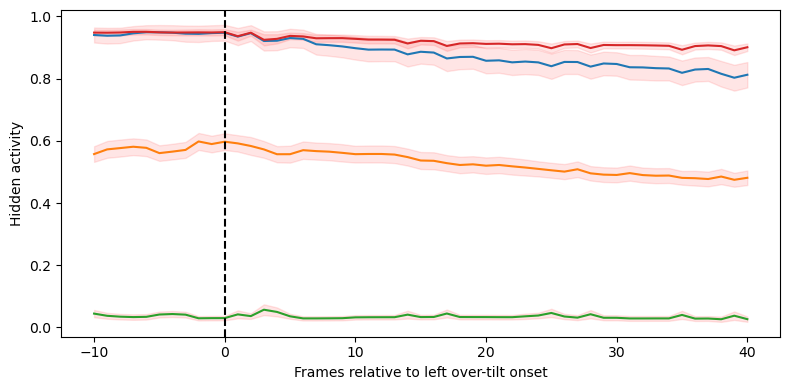

(3, 51) (3, 51) (3,) (34, 3, 51)
Used 34 events


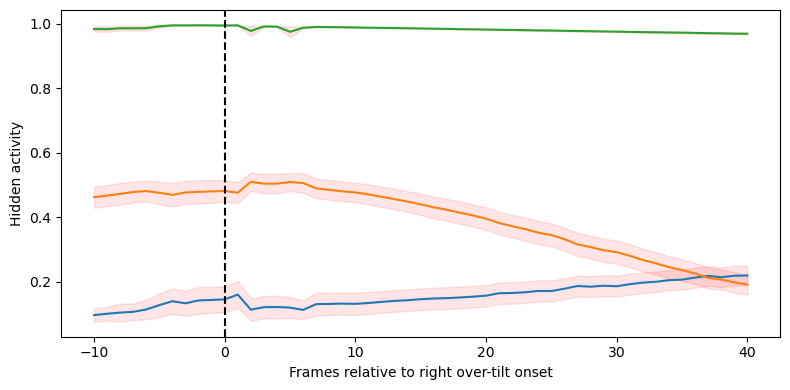

In [30]:
def find_event_onsets(mask: np.ndarray, min_gap: int = 5) -> np.ndarray:
    """
    Find onset indices where mask goes from False -> True.
    min_gap: require at least this many frames of False before a new onset.
    """
    mask = mask.astype(bool)
    onsets = []
    prev_on = -min_gap
    for t in range(1, len(mask)):
        if mask[t] and not mask[t-1] and (t - prev_on) >= min_gap:
            onsets.append(t)
            prev_on = t
    return np.array(onsets, dtype=int)

def peri_event_hidden(buffer_hidden: np.ndarray,
                      event_mask: np.ndarray,
                      center_neurons: np.ndarray,
                      pre: int = 10,
                      post: int = 20):
    """
    Compute peri-event average activity for selected neurons.
    Returns [len(center_neurons), pre+post+1]
    """
    assert event_mask.shape[0] == buffer_hidden.shape[0]
    onsets = find_event_onsets(event_mask)
    H = len(center_neurons)
    T = pre + post + 1
    acc = []
    count = 0

    for t0 in onsets:
        if t0 - pre < 0 or t0 + post >= buffer_hidden.shape[0]:
            continue
        seg = buffer_hidden[t0-pre:t0+post+1, center_neurons]  # [T, H]
        # print(seg.shape, '==?', T)
        normalized_activity = (seg - seg.min()) / (seg.max() - seg.min() + 1e-10)
        acc.append(normalized_activity.T)
        count += 1
    acc_array = np.array(acc) # [n_events, H, T]
    acc_mean = acc_array.mean(0)
    acc_std = acc_array.std(0)/np.sqrt(acc_array.shape[0]-1)
    return acc_mean, acc_std, count, acc_array

# random_neurons = np.random.choice(np.setdiff1d(np.arange(H), top_left_neurons), size=12)
random_neurons = non_selective_neurons
neurons_to_plot = top_left_neurons
exc_inh_mask_to_plot = exc_inh_mask_left
abnormal_to_plot = event_mask_left
avg_left, std_left, n_events, activity_array = peri_event_hidden(
    buffer_hidden,
    abnormal_to_plot,          # or left_abnormal_corr
    neurons_to_plot,
    pre=10,
    post=40)
print(avg_left.shape, std_left.shape, exc_inh_mask_to_plot.shape, activity_array.shape)
exc_inh_colors = ['blue', 'red']
print("Used", n_events, "events")
import matplotlib.pyplot as plt
time = np.arange(-10, 41)
plt.figure(figsize=(8,4))
for i, n in enumerate(neurons_to_plot):
    plt.plot(time, avg_left[i], label=f'{n}')
    plt.fill_between(time, avg_left[i] - std_left[i], avg_left[i] + std_left[i], alpha=0.1, color=exc_inh_colors[exc_inh_mask_to_plot[i]])
plt.axvline(0, color='k', linestyle='--')
plt.xlabel('Frames relative to left over-tilt onset')
plt.ylabel('Hidden activity')
# plt.legend()
plt.tight_layout()
plt.show()



random_neurons = np.random.choice(np.setdiff1d(np.arange(H), top_right_neurons), size=12)
random_neurons = non_selective_neurons
neurons_to_plot = top_right_neurons
exc_inh_mask_to_plot = exc_inh_mask_right
abnormal_to_plot = event_mask_right
avg_left, std_left, n_events, activity_array = peri_event_hidden(
    buffer_hidden,
    abnormal_to_plot,          # or left_abnormal_corr
    neurons_to_plot,
    pre=10,
    post=40)
print(avg_left.shape, std_left.shape, exc_inh_mask_to_plot.shape, activity_array.shape)
print("Used", n_events, "events")
time = np.arange(-10, 41)
plt.figure(figsize=(8,4))
for i, n in enumerate(neurons_to_plot[:20]):
    plt.plot(time, avg_left[i], label=f'{n}')
    plt.fill_between(time, avg_left[i] - std_left[i], avg_left[i] + std_left[i], alpha=0.1, color=exc_inh_colors[exc_inh_mask_to_plot[i]])
plt.axvline(0, color='k', linestyle='--')
plt.xlabel('Frames relative to right over-tilt onset')
plt.ylabel('Hidden activity')
# plt.legend()
plt.tight_layout()
plt.show()

(34, 3, 51)


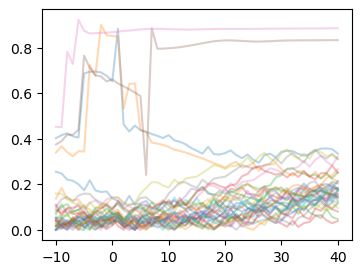

In [31]:
print(activity_array.shape)  # (n_events, H, T)
fig, ax = plt.subplots(1,1,figsize=(4,3))
time = np.arange(-10, 41)
for i in range(activity_array.shape[0]):
    ax.plot(time, activity_array[i,0], alpha=0.3)
    # ax.set_xticks(np.arange(-10, 41))
plt.show()

[3, 2, 1, 58]


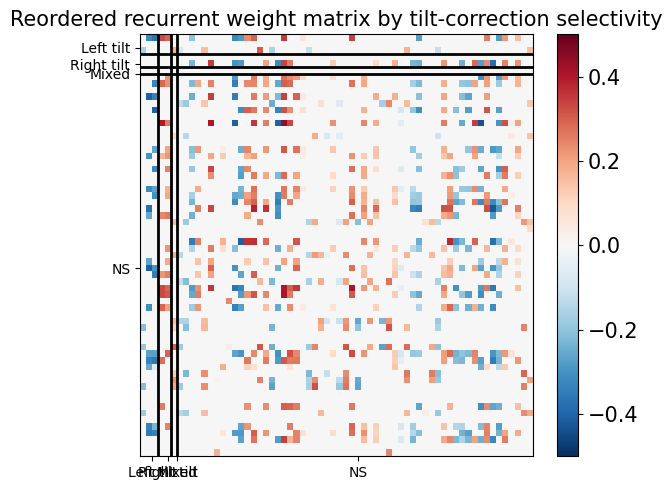

In [32]:
reordered_weight = W[np.ix_(np.concatenate(all_neurons), np.concatenate(all_neurons))]
fig, ax = plt.subplots(1,1,figsize=(6,5))
limit = np.max(np.abs(reordered_weight))
plt.imshow(reordered_weight, cmap='RdBu_r', aspect='auto', vmin=-0.5, vmax=0.5)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=15)
# n_neurons = np.array([len(main_engine_neurons), len(other_choice_neurons), len(mixed_selective_neurons), len(non_selective_neurons)])
phase_boundaries = np.cumsum(group_sizes)
for boundary in phase_boundaries[:-1]:
    plt.axhline(boundary-0.5, color='k', linewidth=2)
    plt.axvline(boundary-0.5, color='k', linewidth=2)
print(group_sizes)
tilt_related_names = ['Left tilt', 'Right tilt', 'Mixed', 'NS']
plt.xticks(phase_boundaries-np.array(group_sizes)/2, tilt_related_names)
plt.yticks(phase_boundaries-np.array(group_sizes)/2, tilt_related_names)
plt.title(f'Reordered recurrent weight matrix by tilt-correction selectivity', fontsize=15)
plt.tight_layout()
plt.show()

4


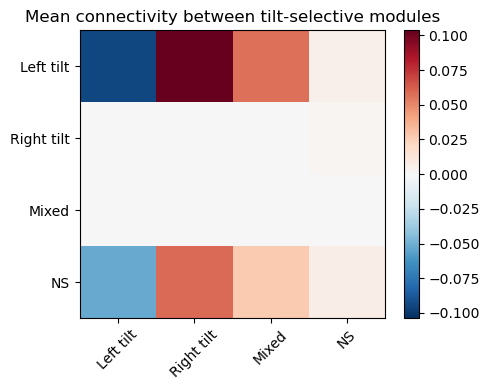

In [33]:
# Build group list: 0..n_phase-1, 'mixed', 'non-selective'
groups = all_neurons
n_groups = len(groups)
print(n_groups)
W_group = np.zeros((n_groups, n_groups))

for p in range(n_groups):        # postsynaptic
    for q in range(n_groups):    # presynaptic
        rows = groups[p]
        cols = groups[q]
        if len(rows) == 0 or len(cols) == 0:
            W_group[p, q] = 0.0
        else:
            sub = W[np.ix_(rows, cols)]
            W_group[p, q] = sub.mean()

fig, ax = plt.subplots(1,1,figsize=(5,4))
limit = np.max(np.abs(W_group))
im = ax.imshow(W_group, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
cbar = plt.colorbar(im)
ax.set_xticks(np.arange(n_groups))
ax.set_yticks(np.arange(n_groups))
ax.set_xticklabels(tilt_related_names, rotation=45)
ax.set_yticklabels(tilt_related_names)
ax.set_title('Mean connectivity between tilt-selective modules')
plt.tight_layout()
plt.show()

See how these correction neurons connect to left engine and right engine


(4, 64)
[3, 2, 1, 58]


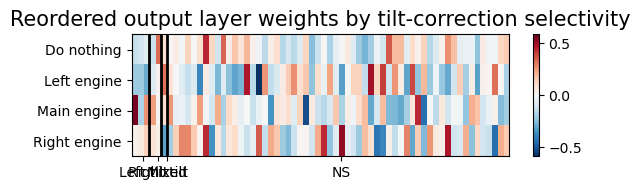

[array([ 3, 17, 52]), array([32, 60]), array([13]), array([ 0,  1,  2,  4,  5,  6,  7,  8,  9, 10, 11, 12, 14, 15, 16, 18, 19,
       20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37,
       38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55,
       56, 57, 58, 59, 61, 62, 63])]
4


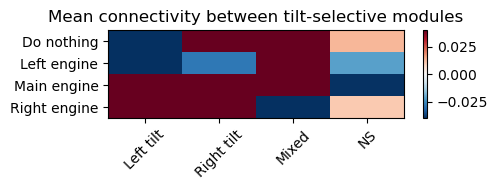

In [34]:
output_layer_weight = agent.actor.output_layer.weight.detach().cpu().numpy()  # [action_dim, hidden_size]
print(output_layer_weight.shape)
fig, ax = plt.subplots(1,1,figsize=(6,2))
reordered_output_weight = output_layer_weight[:, np.concatenate(all_neurons)]
limit = np.max(np.abs(reordered_output_weight))
plt.imshow(reordered_output_weight, cmap='RdBu_r', aspect='auto', vmin=-limit, vmax=limit)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=10)
plt.title('Reordered output layer weights by tilt-correction selectivity', fontsize=15)
phase_boundaries = np.cumsum(group_sizes)
for boundary in phase_boundaries[:-1]:
    # plt.axhline(boundary-0.5, color='k', linewidth=2)
    plt.axvline(boundary-0.5, color='k', linewidth=2)
print(group_sizes)
tilt_related_names = ['Left tilt', 'Right tilt', 'Mixed', 'NS']
actions = ['Do nothing', 'Left engine', 'Main engine', 'Right engine']
plt.xticks(phase_boundaries-np.array(group_sizes)/2, tilt_related_names)
plt.yticks(np.arange(len(actions)), actions)
plt.tight_layout()
plt.show()


# Build group list: 0..n_phase-1, 'mixed', 'non-selective'
groups = all_neurons
print(groups)
n_groups = len(groups)
print(n_groups)
output_layer_group = np.zeros((len(actions), n_groups))

for p in range(len(actions)):        # postsynaptic
    for q in range(n_groups):    # presynaptic
        cols = groups[q]
        if len(cols) == 0:
            output_layer_group[p, q] = 0.0
        else:
            # sub = output_layer_weight[p, cols]
            sub = reordered_output_weight[p, phase_boundaries[q]-group_sizes[q]:phase_boundaries[q]]
            output_layer_group[p, q] = sub.mean()

fig, ax = plt.subplots(1,1,figsize=(5,2))
im = ax.imshow(output_layer_group, cmap='RdBu_r', vmin=-0.04, vmax=0.04, aspect='auto')
cbar = plt.colorbar(im)
ax.set_xticks(np.arange(n_groups))
ax.set_yticks(np.arange(len(actions)))
ax.set_xticklabels(tilt_related_names, rotation=45)
ax.set_yticklabels(actions)
ax.set_title('Mean connectivity between tilt-selective modules')
plt.tight_layout()
plt.show()

In [35]:
import numpy as np
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

def cluster_hidden_regimes(Z, K_min=2, K_max=12, seed=0):
    """
    Z: [T, r] mode coefficients (recommended) or PCA features.
    Returns: labels [T], best_gmm
    """
    Zs = StandardScaler().fit_transform(Z)

    best_model = None
    best_bic = np.inf
    for K in range(K_min, K_max+1):
        gmm = GaussianMixture(n_components=K, covariance_type="full", random_state=seed)
        gmm.fit(Zs)
        bic = gmm.bic(Zs)
        if bic < best_bic:
            best_bic = bic
            best_model = gmm
    print('best K:', best_model.n_components, 'BIC:', best_bic)
    labels = best_model.predict(Zs)
    return labels, best_model

def interpret_clusters(labels, buffer_state, buffer_action, n_actions=4):
    K = int(labels.max()) + 1
    action = buffer_action.reshape(-1).astype(int)

    summaries = []
    for k in range(K):
        idx = (labels == k)
        nk = idx.sum()
        if nk < 10:
            continue

        s = buffer_state[idx]
        a = action[idx]

        state_mean = s.mean(axis=0)
        state_std  = s.std(axis=0)

        # action distribution
        act_counts = np.bincount(a, minlength=n_actions)
        act_prob = act_counts / (act_counts.sum() + 1e-12)

        summaries.append({
            "cluster": k,
            "count": int(nk),
            "state_mean": state_mean,
            "state_std": state_std,
            "action_prob": act_prob,
        })
    return summaries

def transition_matrix(labels):
    K = int(labels.max()) + 1
    T = np.zeros((K, K), dtype=np.float64)
    for t in range(len(labels)-1):
        T[labels[t], labels[t+1]] += 1
    T = T / (T.sum(axis=1, keepdims=True) + 1e-12)
    return T
pca = PCA(n_components=10)
hidden_pca = pca.fit_transform(buffer_hidden)
cluster_labels, gmm_model = cluster_hidden_regimes(hidden_pca, K_min=2, K_max=12, seed=0)
print("Cluster labels shape:", cluster_labels.shape)
print("Cluster label counts:", np.bincount(cluster_labels))
summaries = interpret_clusters(cluster_labels, buffer_state, buffer_action, n_actions=n_action)
for summary in summaries:
    print(f"Cluster {summary['cluster']}: count={summary['count']}")
    print(f"  State mean: {summary['state_mean']}")
    print(f"  State std:  {summary['state_std']}")
    print(f"  Action prob: {summary['action_prob']}")


best K: 11 BIC: -90726.85619233159
Cluster labels shape: (7706,)
Cluster label counts: [1085  704 1168   20  338  385 1356  982  232 1244  192]
Cluster 0: count=1085
  State mean: [ 0.13576433  1.10154692  0.07357706 -0.23586544  0.0550068  -0.01934542
  0.          0.        ]
  State std:  [0.10500246 0.22694157 0.17036678 0.07618024 0.08844958 0.11965163
 0.         0.        ]
  Action prob: [0.04608295 0.20092166 0.56129032 0.19170507]
Cluster 1: count=704
  State mean: [ 0.12276403  1.15616994  0.11750759 -0.0749464   0.06586926  0.03575788
  0.          0.        ]
  State std:  [0.11272629 0.31074136 0.18638098 0.11690566 0.08423937 0.11019348
 0.         0.        ]
  Action prob: [0.04829545 0.25710227 0.39204545 0.30255682]
Cluster 2: count=1168
  State mean: [-0.08892505 -0.00835576 -0.09261377  0.00236316  0.02584687  0.01747696
  0.98886986  0.98886986]
  State std:  [0.17082096 0.00905494 0.06673293 0.01194617 0.07803417 0.03115268
 0.10491071 0.10491071]
  Action prob: 

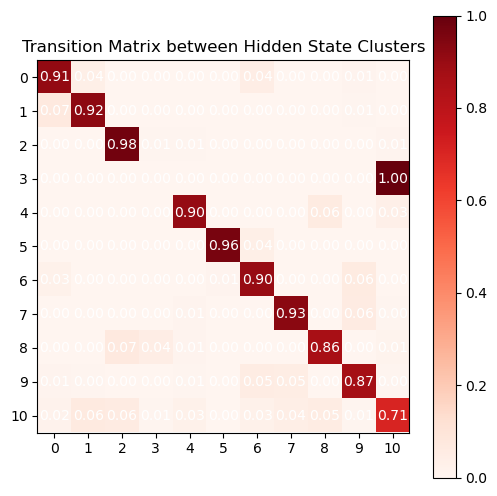

In [36]:
T = transition_matrix(cluster_labels)
fig, ax = plt.subplots(1,1,figsize=(6,6))
im = ax.imshow(T, cmap='Reds', vmin=0, vmax=1)
ax.set_xticks(np.arange(T.shape[0]))
ax.set_yticks(np.arange(T.shape[0]))
for i in range(T.shape[0]):
    for j in range(T.shape[1]):
        text = ax.text(j, i, f'{T[i, j]:.2f}',
                       ha="center", va="center", color="w")
fig.colorbar(im)
ax.set_title('Transition Matrix between Hidden State Clusters')
plt.show()

In [44]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from hmmlearn import hmm

def fit_hmm_gaussian(Z, done, n_components=8, cov_type="full", n_iter=200, seed=0):
    """
    Z: [T, r] latent features (mode coefficients / PCA of hidden)
    done: [T] bool/int, 1 at terminal steps (episode boundary)
    """
    Z = np.asarray(Z)
    done = np.asarray(done).reshape(-1).astype(bool)

    # Build lengths: split at done==1
    ends = np.where(done)[0]
    # Assume done marks the last step of an episode
    lengths = []
    start = 0
    for e in ends:
        L = (e - start + 1)
        if L > 1:
            lengths.append(L)
        start = e + 1
    if start < len(done):  # trailing partial episode
        lengths.append(len(done) - start)

    # Scale features
    scaler = StandardScaler()
    Zs = scaler.fit_transform(Z)

    model = hmm.GaussianHMM(
        n_components=n_components,
        covariance_type=cov_type,   # "full" or "diag"
        n_iter=n_iter,
        random_state=seed,
        verbose=False
    )

    model.fit(Zs, lengths=lengths)

    # Viterbi labels for all timesteps
    labels = model.predict(Zs, lengths=lengths)  # [T]
    post = model.predict_proba(Zs, lengths=lengths)  # [T, K], optional

    return labels, post, model, scaler, lengths
n_components = 8
hmm_labels, hmm_post, hmm_model, hmm_scaler, hmm_lengths = fit_hmm_gaussian(
    buffer_hidden,
    buffer_done,
    n_components=n_components,
    cov_type="full",
    n_iter=200,
    seed=0
)

HMM labels shape: (7706,) (7706, 8) 20
[344, 269, 253, 415, 392, 321, 500, 319, 500, 143, 343, 251, 305, 500, 500, 351, 500, 500, 500, 500]
[1 7 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 6 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2]
[  1   2  25  26 156 174 194]
[  0   1   2  25  26 156 174 194 200]


(-0.5, 199.5, 0.5, -0.5)

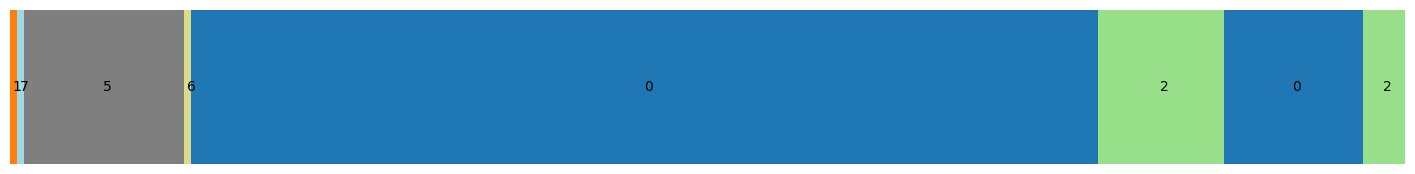

In [68]:
print("HMM labels shape:", hmm_labels.shape, hmm_post.shape, len(hmm_lengths) )
print(hmm_lengths)
fig, ax = plt.subplots(1,1, figsize=(18,2))
ax.imshow(hmm_labels[np.newaxis, :200], aspect='auto', cmap='tab20', vmin=0, vmax=n_components-1)
print(hmm_labels[:200])
boundaries = np.where(np.diff(hmm_labels[:200]))[0]+1
print(boundaries)
zero_plus_boundaries = np.concatenate(([0], boundaries, [200]))
print(zero_plus_boundaries)
centers = (zero_plus_boundaries[:-1] + zero_plus_boundaries[1:]) / 2
for i, c in enumerate(centers):
    ax.text(c, 0, hmm_labels[zero_plus_boundaries[i]], color='k', ha='center', va='center')
ax.axis('off')

1. 分出训练集和测试集
2. 报告 logll
3. 和 episode 一起展示
